# Lesson 5: Using the emulator, under the hood

The trained emulator is a file of arrays. This lesson predicts with nothing but those arrays, tests the result, measures where it fails and how fast it is, uses it on atmosphere profiles, and computes its derivatives with respect to the inputs, which a gradient-based retrieval needs.

1. Prediction by hand
2. What one prediction costs
3. The final test
4. Where the emulator struggles
5. Speed against FastChem
6. Atmosphere profiles
7. Derivatives with respect to the inputs
8. Refusing to extrapolate
9. Is it good enough?
10. The whole emulator in one file

In [1]:
# 1. Let Python find the emulator package
import sys

sys.path.insert(0, "..")

# 2. Imports
import time

import jax

jax.config.update(
    "jax_enable_x64", True
)  # float64, to compare derivatives with NumPy in Section 7
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np

from emulator import data, evaluate
from emulator.evaluate import PALETTE
from emulator.fastchem_check import GridFastChem
from emulator.trained import TrainedEmulator

# 3. The grid and the test rows
grid = data.load_grid("../training_250k.h5")
inputs, outputs, output_names = grid["inputs"], grid["outputs"], grid["output_names"]
test = data.split_from_labels(grid["split"])["test"]

## 1. Prediction by hand

Prediction is the forward pass with the two transforms around it. For features x (log10 T, log10 P, [M/H], log10 C/O, log10 S/O, log10 N/O):

$$ x' = \frac{2(x - l)}{u - l} - 1, \quad a_1 = \tanh(x' W_1 + b_1), \quad a_2 = \tanh(a_1 W_2 + b_2), \quad a_3 = \tanh(a_2 W_3 + b_3), \quad \hat y' = a_3 W_4 + b_4, $$

$$ \log_{10} \hat y = \max(\sigma \odot \hat y' + \mu,\; F) . $$

Every number in these lines is in the saved file:

In [2]:
# 1. Read every array
with np.load("../runs/emulator.npz") as file:
    stored = {key: file[key] for key in file.files}
W = [stored[f"W_{layer}"].astype(np.float64) for layer in range(4)]
b = [stored[f"b_{layer}"].astype(np.float64) for layer in range(4)]
lower, upper = stored["input_lower"], stored["input_upper"]
mean, std, floor = (
    stored["output_mean"],
    stored["output_std"],
    float(stored["output_log10_floor"]),
)
print("weights:", [w.shape for w in W], "  floor:", floor)

# 2. Predict the 25,000 test models
features = inputs[test]  # (25000, 6)
a = 2.0 * (features - lower) / (upper - lower) - 1.0  # x', (25000, 6)
a = np.tanh(a @ W[0] + b[0])  # (25000, 256)
a = np.tanh(a @ W[1] + b[1])  # (25000, 256)
a = np.tanh(a @ W[2] + b[2])  # (25000, 256)
y_scaled = a @ W[3] + b[3]  # (25000, 19)
log10_pred_by_hand = np.maximum(y_scaled * std + mean, floor)  # (25000, 19)

weights: [(6, 256), (256, 256), (256, 256), (256, 19)]   floor: -15.0


**Check** against `TrainedEmulator`, the package class that a retrieval code would use (it needs only NumPy):

In [3]:
emulator = TrainedEmulator("../runs/emulator.npz")
log10_pred = emulator.predict_log10(features)
print("largest difference:", np.abs(log10_pred - log10_pred_by_hand).max(), "dex")

largest difference: 0.0 dex


## 2. What one prediction costs

One model costs one multiply-add per weight: 6 × 256 + 256 × 256 + 256 × 256 + 256 × 19 = 137,472, plus 768 tanh evaluations. Predicting many models at once turns the vector–matrix products into matrix–matrix products, which a CPU does far more efficiently per model:

In [4]:
# 1. Multiply-adds per layer
print("multiply-adds per model:", sum(w.shape[0] * w.shape[1] for w in W))

# 2. Time per model, for different numbers of models per call
for n_models in [1, 100, 10_000]:
    batch = features[:n_models]
    repeats = max(1, 20_000 // n_models)
    start = time.perf_counter()
    for repeat in range(repeats):
        emulator.predict_log10(batch)
    seconds = (time.perf_counter() - start) / (repeats * n_models)
    print(f"{n_models:6d} models per call: {1e6 * seconds:8.2f} microseconds per model")

multiply-adds per model: 137472


     1 models per call:    37.45 microseconds per model
   100 models per call:     4.45 microseconds per model
 10000 models per call:     4.24 microseconds per model


## 3. The final test

The test set has played no part in training or in any choice we made, so its errors are an honest estimate of how the emulator will do on new inputs inside the grid's range, and we look at it only once.

In [5]:
# 1. The truth, floored like the training targets
log10_true = np.maximum(outputs[test], floor)

# 2. Two tables: abundances that matter, and every model
stats = evaluate.error_statistics(log10_true, log10_pred, output_names, threshold=-12.0)
print(
    evaluate.format_error_table(
        stats, "TEST SET, where the true or predicted VMR > 1e-12"
    )
)
print()
print("summary:", evaluate.summary_errors(log10_true, log10_pred))

TEST SET, where the true or predicted VMR > 1e-12
output         n   median      95%      99%      max  [dex]
H           9987   0.0201   0.0810   0.1260    0.259
H2         25000   0.0015   0.0080   0.0158    0.083
H-          4554   0.0133   0.0449   0.0660    0.142
e-          7344   0.0169   0.0644   0.1055    0.239
He         25000   0.0002   0.0010   0.0021    0.007
H2O        20075   0.0233   0.1057   0.1893    0.888
CO         12045   0.0206   0.0815   0.1301    0.364
CO2        11238   0.0255   0.1070   0.2285    1.027
CH4        21972   0.0169   0.0773   0.1614    0.975
C2H2        3648   0.0379   0.2485   0.6229    1.947
Fe          8052   0.0284   0.1269   0.2061    0.571
TiO         5463   0.0348   0.2065   0.3883    3.294
SiO         7744   0.0405   0.1929   0.3836    1.848
HCN         7972   0.0227   0.1165   0.2598    0.963
NH3        20688   0.0245   0.1227   0.3113    4.838
N2         15467   0.0237   0.0940   0.1573    0.644
H2S        17643   0.0489   0.3610   0.996

summary: {'median': 0.02227162050588042, 'p99': 0.241175744016172}


In this table the median column is the typical error, the 95% and 99% columns describe the bad cases, and max is the single worst model out of 25,000. The `mu` row is the mean molecular weight, which sets the scale height, and an error of 0.001 dex there is 0.2%.

## 4. Where the emulator struggles

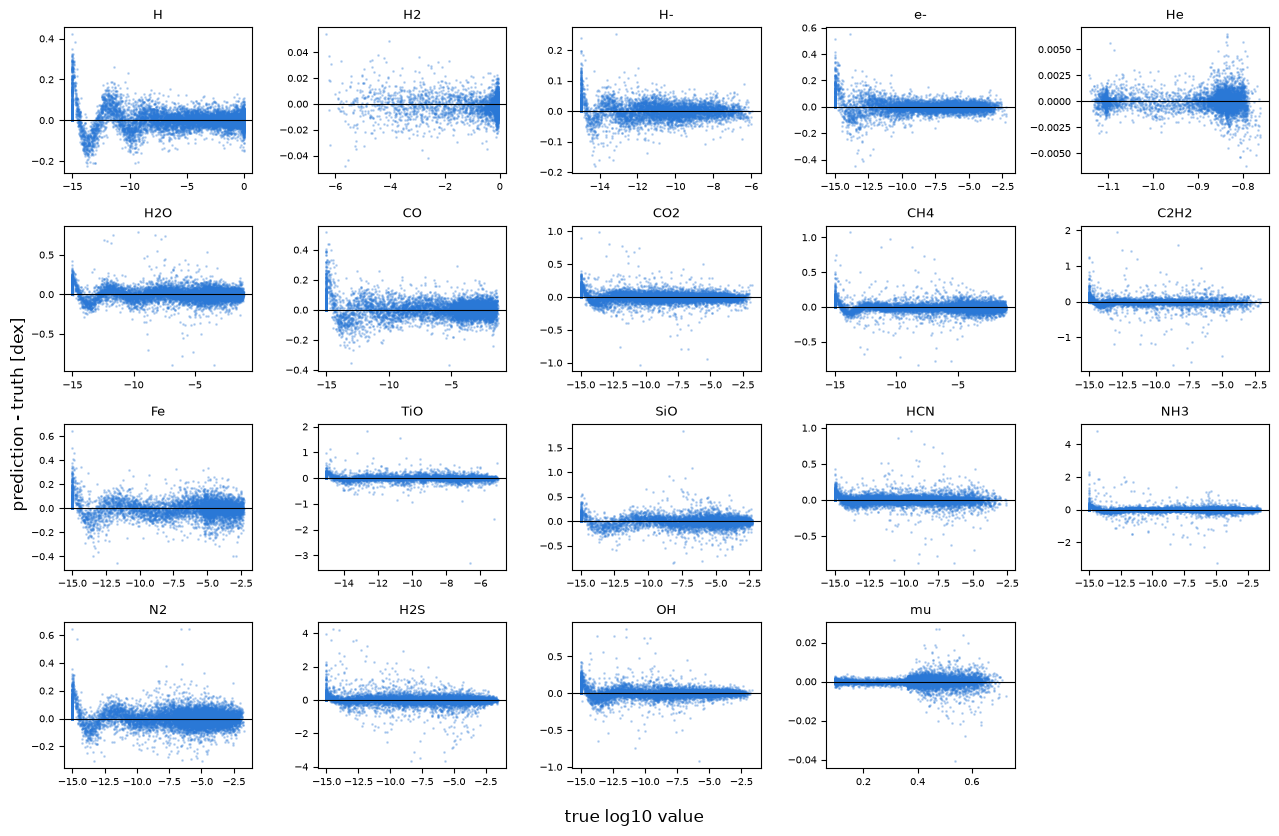

In [6]:
fig = evaluate.plot_residuals_vs_true(log10_true, log10_pred, output_names)
plt.show()

The largest residuals sit just above the floor at −15, where a species switches on or off and the network has to turn a sharp corner. The error against each input, with one line per output and the four outputs with the largest errors in colour:

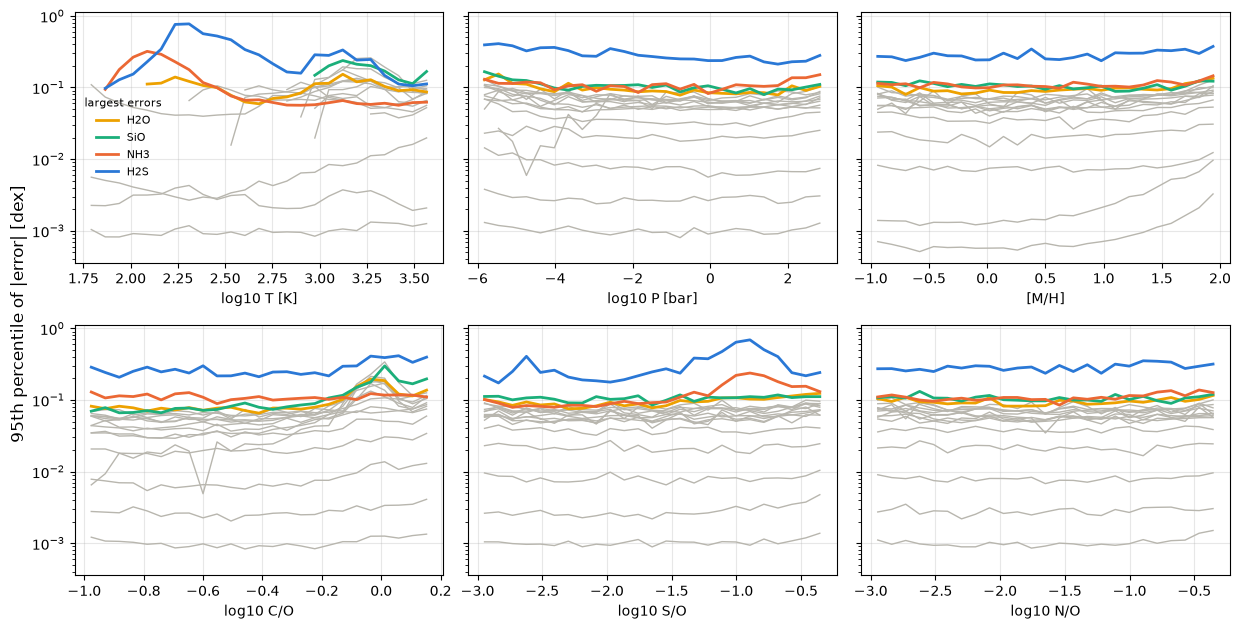

In [7]:
# 1. |error| per model and output, counted only where the abundance matters
abs_error = np.abs(log10_pred - log10_true)
counts = np.maximum(log10_true, log10_pred) > -12.0
abs_error_counted = np.where(counts, abs_error, 0.0)

# 2. 95th percentile of |error| in bins of each input
labels = [
    "log10 T [K]",
    "log10 P [bar]",
    "[M/H]",
    "log10 C/O",
    "log10 S/O",
    "log10 N/O",
]
fig = evaluate.plot_error_vs_input(features, abs_error_counted, labels, output_names)
plt.show()

H2S has the largest errors, below about 250 K and near S/O ≈ 0.1. The grid file shows why: below about 700 K most of the sulfur condenses (mainly as FeS, with FeS2, Ni3S2 and MnS), so the H2S left in the gas is set by a succession of sulfide condensates, each adding a kink that the network has to follow. The ten worst single predictions:

In [8]:
# 1. The ten largest counted errors
flat = np.argsort(abs_error_counted, axis=None)[::-1][:10]
rows, columns = np.unravel_index(flat, abs_error_counted.shape)

# 2. Print them with their inputs
print(
    f"{'output':6s} {'error':>6s} {'true':>7s} {'pred':>7s}   T [K]  log P  [M/H]    C/O"
)
for row, column in zip(rows, columns):
    print(
        f"{output_names[column]:6s} {abs_error[row, column]:6.2f} {log10_true[row, column]:7.2f} "
        f"{log10_pred[row, column]:7.2f}   {10 ** features[row, 0]:5.0f}  {features[row, 1]:5.1f}  "
        f"{features[row, 2]:5.2f}  {10 ** features[row, 3]:5.2f}"
    )

output  error    true    pred   T [K]  log P  [M/H]    C/O
H2S      5.85  -15.00   -9.15      94   -2.7   1.22   0.11
NH3      4.84  -14.41   -9.57     105   -2.2   1.83   0.10
NH3      4.77   -7.77  -12.54      94   -2.7   1.22   0.11
H2S      4.25  -14.47  -10.22     223    2.1   1.72   0.35
H2S      4.21  -14.03   -9.82     140   -5.1  -0.41   0.17
NH3      4.02  -15.00  -10.98      98   -3.4  -0.65   0.10
H2S      3.95  -15.00  -11.05     208    2.6   1.24   0.96
H2S      3.68   -5.73   -9.40     155   -3.2   0.20   0.10
H2S      3.66   -8.38  -12.05      89    0.3   1.82   0.46
H2S      3.61  -14.63  -11.02     223    2.2  -0.43   0.27


## 5. Speed against FastChem

`GridFastChem` (in `emulator/fastchem_check.py`) sets FastChem up exactly as the grid generator did, using the tables stored in the grid file, and recomputing grid models reproduces the stored values to better than 10⁻⁶ dex.

One warning about FastChem on a Mac: the pyfastchem 4.0.4 wheel that `pip` installs on Apple Silicon is compiled without optimization and runs 10 to 40 times slower than the same code compiled with `-O3`, while giving identical results. The `emulator` environment used here has FastChem 4.0.4 built from source with `-O3` (the README gives the commands), so these are fair timings.

In [9]:
# 1. FastChem with the grid's tables and settings (tables written to runs/fastchem_tables)
fastchem = GridFastChem("../training_250k.h5", "../runs/fastchem_tables")

# 2. A 100-layer atmosphere: one composition, temperature rising with pressure
n_layers = 100
log10_pressure = np.linspace(-6.0, 2.0, n_layers)
temperature = 1200.0 + 800.0 * 0.5 * (1.0 + np.tanh(log10_pressure / 1.5))
solar = {
    element: fastchem.solar[fastchem.element_index[element]]
    for element in ("C", "N", "O", "S")
}
composition = [
    1.0,
    np.log10(solar["C"] / solar["O"]),
    np.log10(solar["S"] / solar["O"]),
    np.log10(solar["N"] / solar["O"]),
]
profile = np.column_stack(
    [np.log10(temperature), log10_pressure, np.tile(composition, (n_layers, 1))]
)
print(
    "[M/H] = 1, solar ratios: C/O = %.2f, S/O = %.3f, N/O = %.2f"
    % tuple(10 ** np.array(composition[1:]))
)

# 3. FastChem with condensation (as in the grid) and gas only, then the emulator
start = time.perf_counter()
fastchem_profile, converged = fastchem.compute(profile)
condensation_seconds = time.perf_counter() - start

start = time.perf_counter()
gas_only_profile, _ = fastchem.compute(profile, condensation=False)
gas_only_seconds = time.perf_counter() - start

start = time.perf_counter()
for repeat in range(100):
    emulator_profile = emulator.predict_log10(profile)
emulator_seconds = (time.perf_counter() - start) / 100

# 4. Report
print(
    f"FastChem, condensation: {condensation_seconds:8.4f} s for {n_layers} layers (all converged: {converged.all()})"
)
print(f"FastChem, gas only    : {gas_only_seconds:8.4f} s for {n_layers} layers")
print(f"emulator              : {emulator_seconds:8.5f} s for {n_layers} layers")
print(
    f"speed-up: {condensation_seconds / emulator_seconds:,.0f} times against condensation, {gas_only_seconds / emulator_seconds:,.0f} times against gas only"
)

[M/H] = 1, solar ratios: C/O = 0.55, S/O = 0.027, N/O = 0.14
FastChem, condensation:   0.1153 s for 100 layers (all converged: True)
FastChem, gas only    :   0.0122 s for 100 layers
emulator              :  0.00044 s for 100 layers
speed-up: 261 times against condensation, 28 times against gas only


FastChem runs the layers of one profile in parallel on all cores, while the emulator here is a single NumPy call, and both numbers are wall-clock times on this laptop. Beyond speed, the emulator cannot fail to converge in the middle of a retrieval, and it is differentiable (Section 7).

## 6. Atmosphere profiles

The profile above is new to the emulator: the training set never contained this composition or this run of temperatures. Here are the emulator and FastChem side by side, with a cooler atmosphere where water condenses near the top.

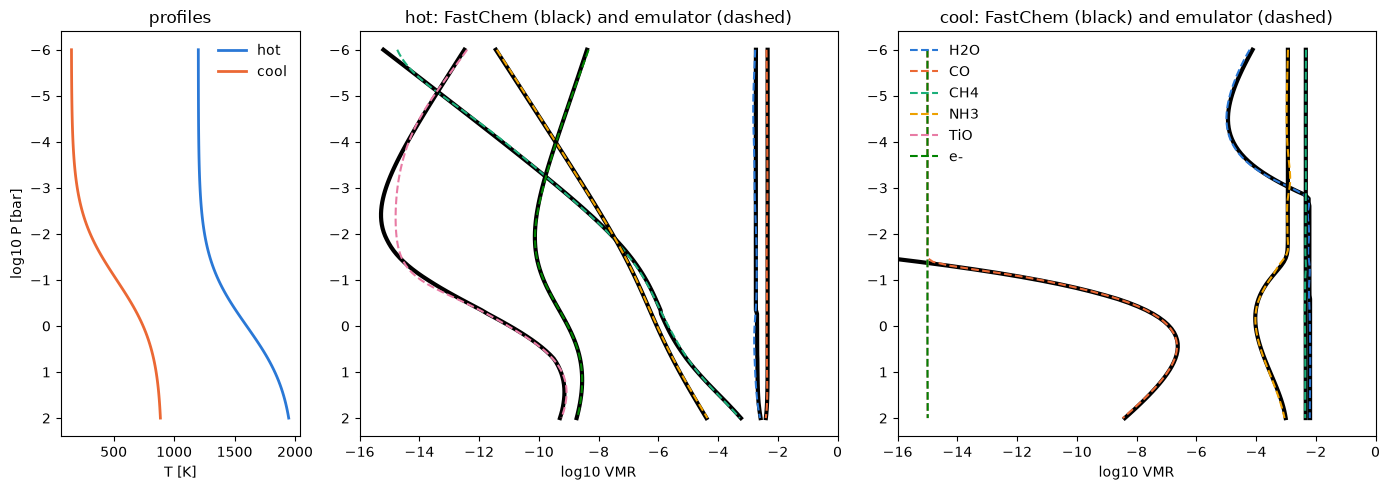

In [10]:
# 1. A cool profile (150 K at the top to 900 K at the bottom), same composition
cool_temperature = 150.0 + 750.0 * 0.5 * (1.0 + np.tanh((log10_pressure + 1.0) / 1.5))
cool_profile = profile.copy()
cool_profile[:, 0] = np.log10(cool_temperature)
cool_fastchem, cool_converged = fastchem.compute(cool_profile)
cool_emulator = emulator.predict_log10(cool_profile)

# 2. Plot both atmospheres: abundance against pressure, FastChem as black lines
species = ["H2O", "CO", "CH4", "NH3", "TiO", "e-"]
fig, axes = plt.subplots(1, 3, figsize=(14, 5), gridspec_kw={"width_ratios": [1, 2, 2]})
axes[0].plot(temperature, log10_pressure, color=PALETTE[0], lw=2, label="hot")
axes[0].plot(cool_temperature, log10_pressure, color=PALETTE[1], lw=2, label="cool")
axes[0].set(xlabel="T [K]", ylabel="log10 P [bar]", title="profiles")
axes[0].invert_yaxis()
axes[0].legend(frameon=False)
for ax, title, truth, prediction in [
    (axes[1], "hot", fastchem_profile, emulator_profile),
    (axes[2], "cool", cool_fastchem, cool_emulator),
]:
    for colour, name in zip(PALETTE, species):
        column = output_names.index(name)
        ax.plot(truth[:, column], log10_pressure, color="black", lw=3)
        ax.plot(
            prediction[:, column],
            log10_pressure,
            color=colour,
            lw=1.5,
            ls="--",
            label=name,
        )
    ax.set(
        xlabel="log10 VMR",
        title=f"{title}: FastChem (black) and emulator (dashed)",
        xlim=(-16, 0),
    )
    ax.invert_yaxis()
axes[2].legend(frameon=False, loc="upper left")
fig.tight_layout()
plt.show()

The emulator follows FastChem through the CO-CH4 switch, the condensation of water at the top of the cool profile and the changing balance between NH3 and N2. The one visible departure is TiO in the hot profile near 5 mbar, where FastChem drops below 10⁻¹⁵ and the emulator stops at the floor it was trained with.

## 7. Derivatives with respect to the inputs

Gradient-based samplers (HMC, NUTS) and sensitivity studies need ∂ log10 X / ∂ inputs. For the network these derivatives are again a chain of matrix products. For one model, write $s_\ell = 1 - a_\ell^2$ for the tanh derivatives of layer ℓ (vectors of 256). Differentiating the forward pass layer by layer gives the Jacobian of the 19 standardized outputs with respect to the 6 scaled inputs:

$$ J = \frac{\partial \hat y'}{\partial x'} = W_1\, \mathrm{diag}(s_1)\, W_2\, \mathrm{diag}(s_2)\, W_3\, \mathrm{diag}(s_3)\, W_4 \qquad (6 \times 19), $$

and the two transforms convert it to physical units: $\partial \log_{10} \hat y_k / \partial x_j = J_{jk}\, \sigma_k\, \dfrac{2}{u_j - l_j}$ (wherever the output is above the floor). Here it is for one layer of the hot profile, at 1 bar:

In [11]:
# 1. One model: the hot-profile layer closest to 1 bar
point = profile[np.argmin(np.abs(log10_pressure))]  # (6,)

# 2. Forward pass for this model, keeping the tanh derivatives s = 1 - a^2
a = 2.0 * (point - lower) / (upper - lower) - 1.0
s = []
for layer in range(3):
    a = np.tanh(a @ W[layer] + b[layer])
    s.append(1.0 - a**2)  # (256,)

# 3. The Jacobian as a chain of matrix products: W1 diag(s1) W2 diag(s2) W3 diag(s3) W4
J = (W[0] * s[0]) @ (W[1] * s[1]) @ (W[2] * s[2]) @ W[3]  # (6, 19)

# 4. Physical units: d log10 y_k / d x_j
derivatives = J * std[None, :] * (2.0 / (upper - lower))[:, None]  # (6, 19)

**Check** it in two independent ways, against JAX's automatic Jacobian of the same forward pass and against central finite differences of the emulator itself:

In [12]:
# 1. JAX: write the forward pass with jnp and let jax.jacobian differentiate it
def log10_outputs(features_one_model):
    """Unfloored log10 outputs of the emulator for one model (JAX version).

    Parameters
    ----------
    features_one_model : jax array, shape (6,)
        The six features of one model.

    Returns
    -------
    log10_values : jax array, shape (19,)
        sigma * y' + mu, before the floor.
    """
    a = 2.0 * (features_one_model - lower) / (upper - lower) - 1.0
    for layer in range(3):
        a = jnp.tanh(a @ W[layer] + b[layer])
    log10_values = (a @ W[3] + b[3]) * std + mean
    return log10_values


jacobian_jax = np.asarray(jax.jacobian(log10_outputs)(jnp.asarray(point))).T  # (6, 19)
print("largest difference from JAX:", np.abs(jacobian_jax - derivatives).max())

# 2. Finite differences of the emulator, one input at a time
h = 1e-5
finite = np.zeros((6, 19))
for j in range(6):
    up, down = point.copy(), point.copy()
    up[j] += h
    down[j] -= h
    finite[j] = (
        emulator.predict_log10(up[None, :])[0]
        - emulator.predict_log10(down[None, :])[0]
    ) / (2.0 * h)

# 3. Outputs at the floor have zero derivative in the emulator, so compare the others
above_floor = emulator.predict_log10(point[None, :])[0] > floor
print(
    "outputs at the floor here:",
    [name for name, keep in zip(output_names, above_floor) if not keep],
)
print(
    "largest difference from finite differences:",
    np.abs(finite - derivatives)[:, above_floor].max(),
)

largest difference from JAX: 4.263256414560601e-14
outputs at the floor here: []
largest difference from finite differences: 2.79207174713747e-07


Some of these sensitivities, at T = 1,600 K, P = 1 bar, [M/H] = +1:

In [13]:
print(f"{'species':7s} {'d/d log10 T':>12s} {'d/d log10 P':>12s} {'d/d [M/H]':>10s}")
for name in ["H2O", "CO", "CH4", "NH3", "TiO", "e-", "mu"]:
    k = output_names.index(name)
    print(
        f"{name:7s} {derivatives[0, k]:12.2f} {derivatives[1, k]:12.2f} {derivatives[2, k]:10.2f}"
    )

species  d/d log10 T  d/d log10 P  d/d [M/H]
H2O            -1.65         0.03       1.03
CO             -0.07        -0.00       1.01
CH4           -15.29         1.93      -0.06
NH3            -4.07         1.00       0.42
TiO            48.86        -0.94      -0.62
e-             18.32        -0.55       0.35
mu             -0.02         0.00       0.08


The emulator has learned the textbook scalings of equilibrium chemistry, although nobody told it any chemistry. When CO holds the carbon, CO + 3H₂ ⇌ CH₄ + H₂O makes CH₄ grow as P² and leaves it nearly independent of metallicity (both CO and H₂O scale with it), and the emulator gives 1.93 and −0.06. N₂ + 3H₂ ⇌ 2NH₃ makes NH₃ grow as P (N/H)^½, against 1.00 and 0.42 here. Thermal ionization (Saha) makes the electron fraction fall as P^(−½), against −0.55, and H₂O and CO scale with metallicity, as the derivatives of 1.03 and 1.01 show. TiO above its condensate is held at a fixed partial pressure, so its mixing ratio falls as 1/P, against −0.94, and its steep rise with temperature (49 dex per dex) is the vapour-pressure curve.

## 8. Refusing to extrapolate

A network returns a number for any input, including inputs far outside its training range, where that number means nothing. After the input transform the training range is exactly [−1, 1] in every column, so the check is one line:

In [14]:
# 1. Three layers at 40 K, below the grid's lowest temperature
too_cold = profile[:3].copy()
too_cold[:, 0] = np.log10(40.0)
x_scaled = 2.0 * (too_cold - lower) / (upper - lower) - 1.0
print(
    "scaled temperature:",
    x_scaled[:, 0].round(3),
    "  outside [-1, 1]:",
    np.any(np.abs(x_scaled) > 1.0 + 1e-3),
)

# 2. TrainedEmulator raises an error instead of predicting
try:
    emulator.predict_log10(too_cold)
except ValueError as error:
    print("ValueError:", error)

scaled temperature: [-1.165 -1.165 -1.165]   outside [-1, 1]: True
ValueError: 3 point(s) outside the training range in ['log10_T_K']; the emulator would be extrapolating


The 10⁻³ margin lets through test models that sit a hair beyond the training extremes (about 10⁻⁵ in scaled units). The check is a box, which is right for this grid because the grid fills its box everywhere above about 60 K.

## 9. Is it good enough?

- Compared with the data: JWST retrievals typically constrain abundances to 0.1 to 0.5 dex, so a typical emulator error of a few hundredths of a dex adds little. The tails matter more, because a 1-dex error at a cliff could bias a retrieval that happens to sit there.
- Compared with the alternative: Lesson 2's table-like interpolation (nearest neighbours) had typical errors of 0.3 dex with this many models.

The first improvements to try are training longer or wider, since the loss was still falling, and adding FastChem models near the cliffs. After those come an ensemble of networks trained from different seeds, whose spread also estimates the emulator's own error at each point, and a check of how far the outputs break element conservation.

## 10. The whole emulator in one file

`from_scratch/emulator_numpy.py` repeats Lessons 1 to 5 in one file of NumPy, with no machine-learning library: it reads the grid, builds the transforms, initializes the weights, and trains with hand-written backpropagation and Adam, then predicts and tests. With its default settings (two hidden layers of 128 units, 40 epochs) it trains in about 20 seconds and reaches a median test error of 0.09 dex. With the settings of this course (three layers of 256, 300 epochs) it matches the JAX emulator, 0.022 dex median and 0.24 dex at the 99th percentile, in about 11 minutes instead of 4, so JAX buys speed while the accuracy stays the same. Reading that file from top to bottom is the best test that every piece of this course is clear.

## Exercises

1. Train a second emulator with `seed=1` in Lesson 4 and average the two predictions on the test set. How much do the errors drop, and where do the two networks disagree most?
2. Compute the Jacobian for every layer of the cool profile and plot ∂ log10 X(H2O)/∂ log10 T against pressure. Where does it jump, and why?
3. For the test set, add up the predicted mixing ratios of H2, He and H. How far from the FastChem sum is it?
4. Use `TrainedEmulator` from an older Python environment (3.8 or later) without JAX: copy the `emulator` folder and the `.npz` file, and predict a profile.